In [1]:
import os
import sys
import json
import subprocess
from pathlib import Path
import torch
from pytorchexample.task import load_data
import matplotlib.pyplot as plt
import ipywidgets as widgets
import numpy as np
# import torch

from pytorchexample.task import load_centralized_dataset

%matplotlib inline

# Find Assignment starting from the notebook's working directory.
cwd = Path.cwd().resolve()
ASSIGNMENT_DIR = next((p for p in (cwd, *cwd.parents) if p.name == "Assignment"), None)
if ASSIGNMENT_DIR is None:
    raise RuntimeError(f"Could not find 'Assignment' above Jupyter cwd: {cwd}")

PROJECT = ASSIGNMENT_DIR / "Part_2-Federated Learning" / "quickstart-pytorch"
RESULTS_DIR = ASSIGNMENT_DIR / "Part_2-Federated Learning" / "resultat"
MODELS_DIR = ASSIGNMENT_DIR / "Part_2-Federated Learning" / "modeller"
LOGS_DIR = ASSIGNMENT_DIR / "Part_2-Federated Learning" / "logs"
FLWR = Path(sys.prefix) / ("Scripts/flwr.exe" if os.name == "nt" else "bin/flwr")




trainloader, testloader = load_data(
    partition_id=0,
    num_partitions=5,
    batch_size=32
)



NUM_ROUNDS = 35
ATTACKER_COUNTS = (0, 1, 2)

if not (PROJECT / "pyproject.toml").is_file():
    raise FileNotFoundError(f"Flower project not found: {PROJECT}")

sys.path.insert(0, str(PROJECT))
from pytorchexample.task import Net, load_data

# # FedAvg: {0: Net(), 1: Net(), 2: Net()}
# models_FedAvg = {
#     "0-attacker": None,
#     "1-attacker": None,
#     "2-attacker": None,
#     "3-attacker": None,
# }

# # FedMedian
# models_FedMedian = {
#     "0-attacker": None,
#     "1-attacker": None,
#     "2-attacker": None,
#     "3-attacker": None,
# }

#########################
#   Model dictionaries  #
#########################
models_FedAvg = {
    "0-attacker": None,
    "1-attacker": None,
    "2-attacker": None,
    "3-attacker": None,
}

models_FedMedian = {
    "0-attacker": None,
    "1-attacker": None,
    "2-attacker": None,
    "3-attacker": None,
}

models_FedTrimmedavg = {
    "0-attacker": None,
    "1-attacker": None,
    "2-attacker": None,
}

models_FedAvgm = {
    "0-attacker": None,
    "2-attacker": None,
}

models_FedYogi = {
    "0-attacker": None,
    "2-attacker": None,
}


##########################
#   Result dictionaries  #
##########################
results_FedAvg = {}
results_FedMedian = {}
results_FedTrimmedavg = {}
results_FedAvgm = {}
results_FedYogi = {}

print("Flower project:", PROJECT)
print("Models:", MODELS_DIR)
print("JSON:", RESULTS_DIR)
print("Flower executable:", FLWR)

Flower project: C:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\quickstart-pytorch
Models: C:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\modeller
JSON: C:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\resultat
Flower executable: c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Scripts\flwr.exe


# Functions for training or loading the models

In [2]:
def experiment_name(attackers: int, aggregation: str = "fedavg") -> str:
    return f"{aggregation}_attack{attackers}_rounds{NUM_ROUNDS}"



def load_model(aggregation: str, attackers: int):
    """Load an existing trained model and its JSON results."""

    name = experiment_name(attackers, aggregation)

    model_path = MODELS_DIR / f"{name}.pt"
    metrics_path = RESULTS_DIR / f"{name}.json"


    model = Net()
    model.load_state_dict(torch.load(model_path, map_location="cpu", weights_only=True))
    model.eval()


    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))

    print(f"Loaded: {name}")

    return model, metrics


def train_model(aggregation: str, attackers: int):
    """Train one experiment, then load its saved model and results."""

    run_flower(aggregation, attackers)

    return load_model(aggregation, attackers)


# Run flower
# def run_flower(aggregation: str, attackers: int):
def run_flower(
    aggregation: str,
    attackers: int,
    num_rounds: int | None = None,
    save_model: bool = True
):
    """Run one experiment synchronously; keep Flower output in a log file."""
    if not FLWR.is_file():
        raise FileNotFoundError(f"Flower CLI is not available in this Jupyter kernel: {FLWR}")

    LOGS_DIR.mkdir(parents=True, exist_ok=True)
    # name = experiment_name(attackers, aggregation)
    rounds = NUM_ROUNDS if num_rounds is None else num_rounds
    name = f"{aggregation}_attack{attackers}_rounds{rounds}"

    log_path = LOGS_DIR / f"{name}.log"

    # # Strings in Flower run-config must have TOML-style quotes.
    config = (
        f'num-server-rounds={rounds} '
        f'num-attacked-clients={attackers} '
        f'strategy-name="{aggregation}" '
        f'save-model={str(save_model).lower()} '
        f'run-name="{aggregation}"'
    )
    # config = (
    #     f'num-server-rounds={NUM_ROUNDS} '
    #     f'num-attacked-clients={attackers} '
    #     f'use-median={str(aggregation == "fedmedian").lower()} '
    #     f'save-model=true '
    #     # f'run-name="{name}"'
    #     f'run-name="{aggregation}"'
    # )

    env = os.environ.copy()
    env["FLWR_HOME"] = str(Path.home() / ".flwr_dv2607_terminal")
    env["FLWR_LOCAL_SUPERLINK_HTTP_API_PORT"] = "39125"
    env["FLWR_DISABLE_RUNTIME_DEPENDENCY_INSTALLATION"] = "1"

    cmd = [
        str(FLWR), "run", ".",
        "--federation-config", "num-supernodes=5",
        "--run-config", config,
        "--stream",
    ]
    print(f"Training {name} ... (details: {log_path})", flush=True)
    with log_path.open("w", encoding="utf-8") as log_file:
        result = subprocess.run(
            cmd, cwd=PROJECT, env=env,
            stdout=log_file, stderr=subprocess.STDOUT,
            check=False,
        )
    if result.returncode != 0:
        tail = "\n".join(log_path.read_text(encoding="utf-8", errors="replace").splitlines()[-20:])
        raise RuntimeError(f"Flower failed for {name} (exit {result.returncode}).\n{tail}")
    print(f"Flower command finished: {name}")



In [3]:
# FedAvg — your original for-loop pattern
for attackers, model_key in enumerate(models_FedAvg):
    try:
        models_FedAvg[model_key], results_FedAvg[model_key] = load_model("fedavg", attackers)
        print(f"Loaded FedAvg / {attackers} attacker(s)")
    except FileNotFoundError:
        models_FedAvg[model_key], results_FedAvg[model_key] = train_model("fedavg", attackers)


print("\nFedAvg models:", [k for k, v in models_FedAvg.items() if v is not None])

Loaded: fedavg_attack0_rounds35
Loaded FedAvg / 0 attacker(s)
Loaded: fedavg_attack1_rounds35
Loaded FedAvg / 1 attacker(s)
Loaded: fedavg_attack2_rounds35
Loaded FedAvg / 2 attacker(s)
Loaded: fedavg_attack3_rounds35
Loaded FedAvg / 3 attacker(s)

FedAvg models: ['0-attacker', '1-attacker', '2-attacker', '3-attacker']


In [4]:


class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Select trained baseline model (0 attackers)
# model = models_FedAvg["0-attacker"]

malicous_clients = list(sorted(models_FedAvg.keys()))


from pytorchexample.task import load_centralized_dataset

# Load test data once
testloader = load_centralized_dataset()

samples = {3: [], 5: []}

for batch in testloader:
    for image, label in zip(batch["img"], batch["label"]):
        label = int(label)

        if label in samples and len(samples[label]) < 4:
            samples[label].append((image, label))

    if all(len(v) == 4 for v in samples.values()):
        break

selected_samples = samples[3] + samples[5]
images = torch.stack([image for image, _ in selected_samples])



def visualize_predictions(model_key ="0-attacker", models = models_FedAvg, strategy = "FedAvg"):

    # Select model from dictionary
    model = models[model_key]

    if model is None:
        print(f"Model {model_key} is not loaded.")
        return

    model.eval()

    # Run predictions
    with torch.no_grad():
        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, predictions = probabilities.max(dim=1)

    # Visualize
    fig, axs = plt.subplots(2, 4, figsize=(12, 6))

    for i, ax in enumerate(axs.flat):
        image, true_label = selected_samples[i]

        predicted_label = int(predictions[i])
        conf = float(confidence[i])

        image = image.permute(1, 2, 0).numpy()
        image = np.clip(image / 2 + 0.5, 0, 1)

        ax.imshow(image)

        ax.set_title(
            f"{class_names[true_label]} → {class_names[predicted_label]}\n"
            f"Confidence: {conf:.1%}",
            color="green" if true_label == predicted_label else "red"
        )

        ax.axis("off")

    plt.suptitle(f"{strategy} – {model_key}")
    plt.tight_layout()
    plt.show()





# Function for plotting kappa and F1 side by side, suporting changing strategies.
def plot_kappa_and_F1(strategies: dict):

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, metric in zip(axes, ["f1", "kappa"]):

        for i, (strategy, results) in enumerate(strategies.items()):

            for attackers in range(3):

                key = f"{attackers}-attacker"

                if key not in results:
                    continue

                data = results[key]

                rounds = sorted(int(r) for r in data.keys())
                values = [float(data[str(r)][metric]) for r in rounds]

                ax.plot(
                    rounds,
                    values,
                    label=f"{strategy} - {attackers} attacker(s)",
                    # linestyle="-" if i == 0 else "--"
                    linestyle=["-", "--", ":"][i]
                )

        ax.set_xlabel("Communication round")
        ax.set_ylabel(metric.upper())
        ax.set_title(f"{metric.upper()} across communication rounds")
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()




In [5]:

widgets.interact(
    visualize_predictions,
    model_key=widgets.Dropdown(
        # options=sorted(models_FedAvg.keys()),
        options=malicous_clients,
        value="0-attacker",
        description="Attackers:"
    ),
    models=widgets.fixed(models_FedAvg),
    strategy=widgets.fixed("FedAvg")
);

interactive(children=(Dropdown(description='Attackers:', options=('0-attacker', '1-attacker', '2-attacker', '3…

In [6]:
import time

cooldown = 90  # Seconds (1.5 minutes)
trained_before = False

# FedMedian
for attackers, model_key in enumerate(models_FedMedian):
    try:
        models_FedMedian[model_key], results_FedMedian[model_key] = load_model(
            "fedmedian", attackers
        )
        print(f"Loaded FedMedian / {attackers} attacker(s)")

    except FileNotFoundError:

        # Cooldown between training runs
        if trained_before:
            print(f"Cooling down for {cooldown} seconds...")
            time.sleep(cooldown)

        print(f"Training FedMedian / {attackers} attacker(s)")

        models_FedMedian[model_key], results_FedMedian[model_key] = train_model(
            "fedmedian", attackers
        )

        trained_before = True

print("FedMedian models:", [
    k for k, v in models_FedMedian.items() if v is not None
])

Loaded: fedmedian_attack0_rounds35
Loaded FedMedian / 0 attacker(s)
Loaded: fedmedian_attack1_rounds35
Loaded FedMedian / 1 attacker(s)
Loaded: fedmedian_attack2_rounds35
Loaded FedMedian / 2 attacker(s)
Loaded: fedmedian_attack3_rounds35
Loaded FedMedian / 3 attacker(s)
FedMedian models: ['0-attacker', '1-attacker', '2-attacker', '3-attacker']


In [ ]:
widgets.interact(
    visualize_predictions,
    model_key=widgets.Dropdown(
        options=malicous_clients,
        value="0-attacker",
        description="Attackers:"
    ),
    models=widgets.fixed(models_FedMedian),
    strategy=widgets.fixed("FedMedian")
);

interactive(children=(Dropdown(description='Attackers:', options=('0-attacker', '1-attacker', '2-attacker', '3…

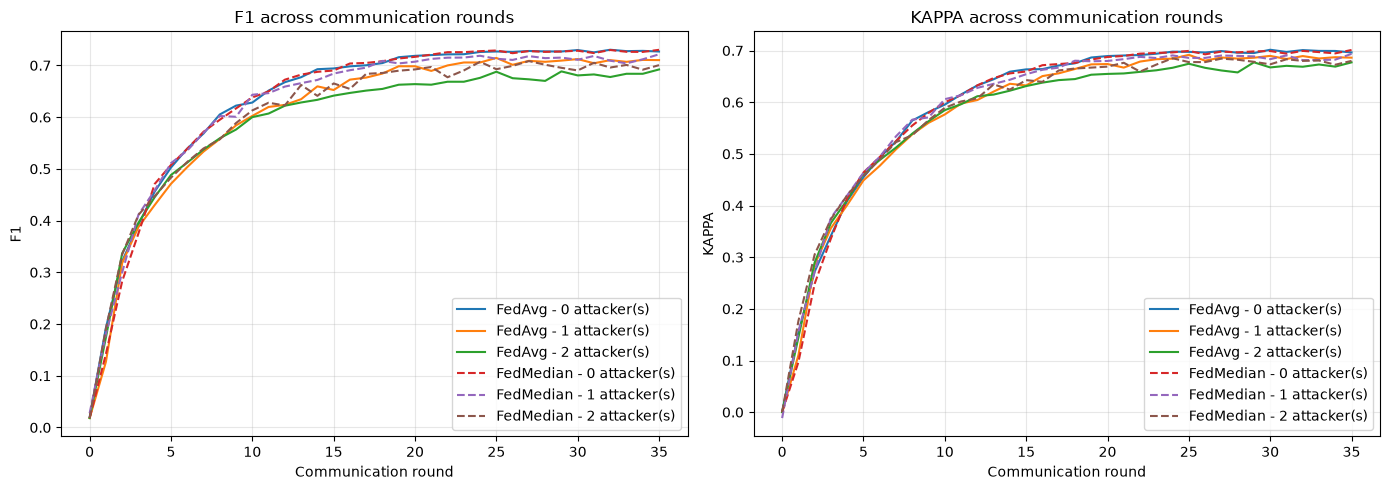

In [8]:
plot_kappa_and_F1({
    "FedAvg": results_FedAvg,
    "FedMedian": results_FedMedian
})

In [10]:
# 2.3 – FedAvgM
for model_key in models_FedAvgm:
    attackers = int(model_key.split("-")[0])

    try:
        models_FedAvgm[model_key], results_FedAvgm[model_key] = load_model(
            "fedavgm", attackers
        )
    except FileNotFoundError:
        models_FedAvgm[model_key], results_FedAvgm[model_key] = train_model(
            "fedavgm", attackers
        )

Loaded: fedavgm_attack0_rounds35
Loaded: fedavgm_attack2_rounds35


In [11]:
# 2.3 – FedYogi
for model_key in models_FedYogi:
    attackers = int(model_key.split("-")[0])

    try:
        models_FedYogi[model_key], results_FedYogi[model_key] = load_model(
            "fedyogi", attackers
        )
    except FileNotFoundError:
        models_FedYogi[model_key], results_FedYogi[model_key] = train_model(
            "fedyogi", attackers
        )

Loaded: fedyogi_attack0_rounds35
Loaded: fedyogi_attack2_rounds35


In [13]:
# 2.4 – FedTrimmedAvg
for attackers, model_key in enumerate(models_FedTrimmedavg):
    try:
        models_FedTrimmedavg[model_key], results_FedTrimmedavg[model_key] = load_model(
            "fedtrimmedavg", attackers
        )
    except FileNotFoundError:
        models_FedTrimmedavg[model_key], results_FedTrimmedavg[model_key] = train_model(
            "fedtrimmedavg", attackers
        )

Loaded: fedtrimmedavg_attack0_rounds35
Loaded: fedtrimmedavg_attack1_rounds35
Loaded: fedtrimmedavg_attack2_rounds35


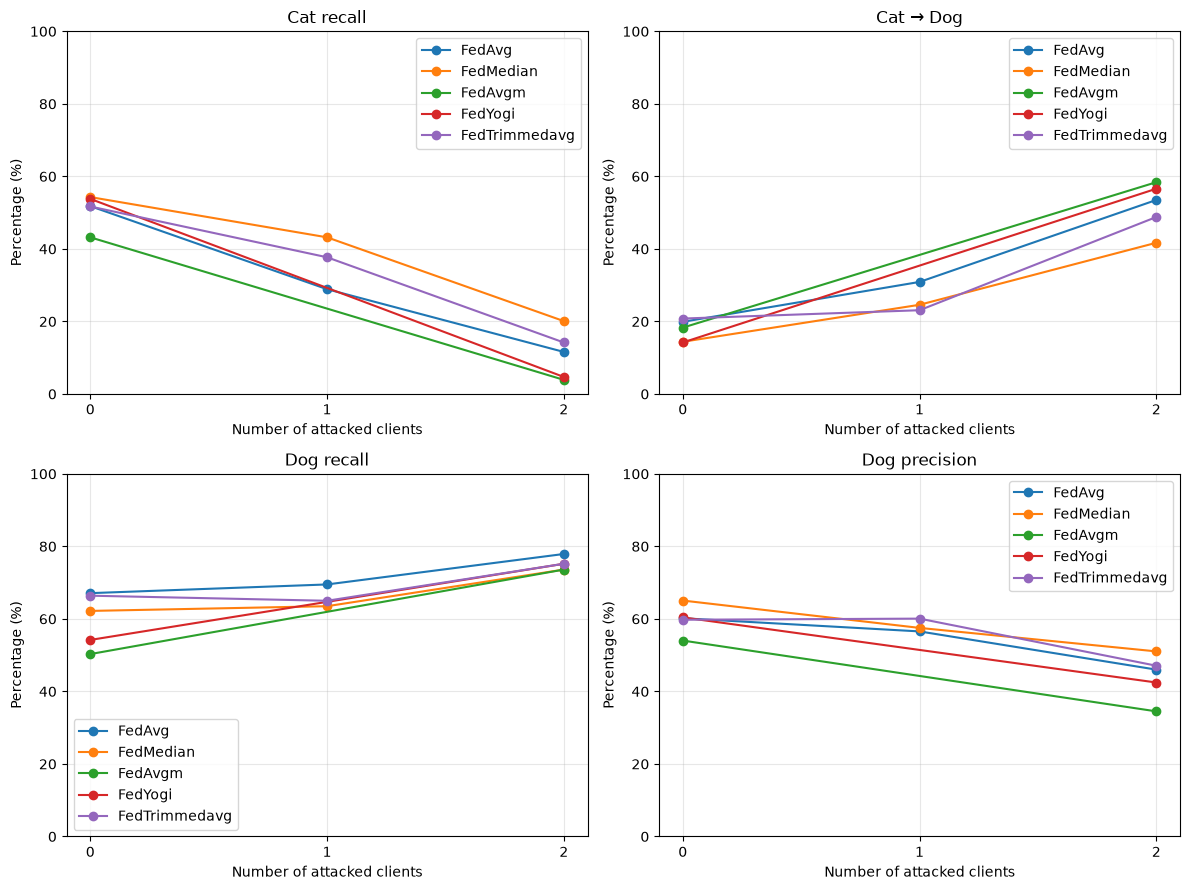

In [14]:

# testloader = load_centralized_dataset()


def evaluate_cat_dog(model):

    y_true = []
    y_pred = []

    model.eval()

    with torch.no_grad():
        for batch in testloader:

            images = batch["img"]
            labels = batch["label"]

            predictions = model(images).argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    cats = y_true == 3
    dogs = y_true == 5
    predicted_dogs = y_pred == 5

    return {
        "Cat recall": np.mean(y_pred[cats] == 3),
        "Cat → Dog": np.mean(y_pred[cats] == 5),
        "Dog recall": np.mean(y_pred[dogs] == 5),
        "Dog precision": (
            np.sum(dogs & predicted_dogs) / np.sum(predicted_dogs)
            if np.any(predicted_dogs) else np.nan
        )
    }


# Evaluate saved models
scores = {}

for strategy, models in {
    "FedAvg": models_FedAvg,
    "FedMedian": models_FedMedian,
    "FedTrimmedavg": models_FedTrimmedavg,
    "FedAvgm": models_FedAvgm,
    "FedYogi": models_FedYogi
}.items():

    # for attackers in range(3):
    for attackers in range(4):

        key = f"{attackers}-attacker"
        model = models.get(key)

        if model is not None:
            scores[(strategy, attackers)] = evaluate_cat_dog(model)


# Plot results
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

metrics = [
    "Cat recall",
    "Cat → Dog",
    "Dog recall",
    "Dog precision"
]

for ax, metric in zip(axes.flat, metrics):

    for strategy in ["FedAvg", "FedMedian", "FedAvgm", "FedYogi", "FedTrimmedavg"]:

        x = [
            n for n in range(3)
            if (strategy, n) in scores
        ]

        y = [
            scores[(strategy, n)][metric] * 100
            for n in x
        ]

        ax.plot(x, y, marker="o", label=strategy)

    ax.set_title(metric)
    ax.set_xlabel("Number of attacked clients")
    ax.set_ylabel("Percentage (%)")
    ax.set_xticks([0, 1, 2])
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

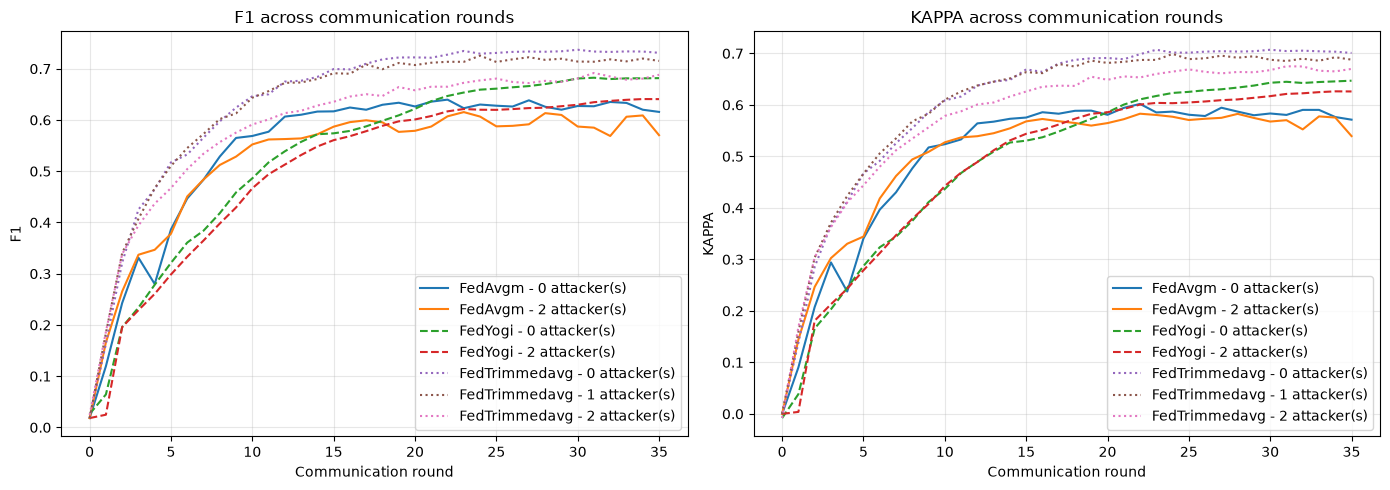

In [15]:
plot_kappa_and_F1({
    "FedAvgm": results_FedAvgm,
    "FedYogi": results_FedYogi,
    "FedTrimmedavg": results_FedTrimmedavg
})

In [16]:
from sklearn.metrics import confusion_matrix
import torch

def verify_cat_dog(model):
    y_true, y_pred = [], []
    model.eval()

    with torch.no_grad():
        for batch in load_centralized_dataset():
            predictions = model(batch["img"]).argmax(dim=1)

            y_true.extend(batch["label"].tolist())
            y_pred.extend(predictions.tolist())

    cm = confusion_matrix(y_true, y_pred, labels=range(10))

    print("Cat samples:", cm[3].sum())
    print("Cat recall:", cm[3, 3] / cm[3].sum())
    print("Cat → Dog:", cm[3, 5] / cm[3].sum())
    print("Dog recall:", cm[5, 5] / cm[5].sum())



verify_cat_dog(models_FedAvg["2-attacker"])


Cat samples: 1000
Cat recall: 0.116
Cat → Dog: 0.535
Dog recall: 0.779
